# Outlier CA phylogeny analysis, scaled up, with a non-replicator control

Repeats the border-versus-middle analysis of [`2026-05-11-hstrat-paper-outlier-plots.ipynb`](2026-05-11-hstrat-paper-outlier-plots.ipynb) with three changes.

1. **Larger run.** The outlier CA is run for $\sqrt{20}\times$ as many steps on a grid with $\sqrt{20}\times$ the side length. The pattern grows at constant speed, so this gives about $20\times$ the extant population (and so $20\times$ the phylogeny tips) of the reference run.
2. **Non-replicator control.** The same pipeline is applied to a second expanding CA, 3-4 Life (B34/S34), which grows from a small seed as a dense chaotic blob rather than by budding off discrete self-copying structures. It is run until its extant population matches the scaled-up outlier run.
3. **Persistence filter in place of a time cutoff.** Rather than cutting trees at a fixed time, every live cell is also sampled at an earlier snapshot. Border and middle regions are laid out on that early snapshot, and each region's tree is built from its lineages that persist, i.e., that have descendants in the final snapshot (see "Parameters" and "Persistence filter").

Unlike the reference notebook, which downloads phylogenies generated on GPU by [`pylib/track_outlier.ipynb`](../pylib/track_outlier.ipynb), both CAs are run here, on CPU, using `pylib.track_ca_fast.FastCATracker`. That class fuses the CA update and hstrat marker inheritance into one compiled pass over live cells, with the same inheritance semantics as `pylib.track_ca.MultiTracker` driven with `dstream_S=64`, `dstream_bitwidth=1`, and `add_random_noise=True` (see its module docstring).


In [1]:
%load_ext watermark


In [2]:
import math
import os
import typing

from downstream import dstream
import matplotlib as mpl
import matplotlib.path
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
from phyloframe import _auxlib as pfa
from phyloframe import legacy as pfl
from scipy import ndimage as scipy_ndimage
from scipy import stats as scipy_stats
import seaborn as sns
from teeplot import teeplot as tp
from tqdm import tqdm

from pylib.persistence_filter import mark_persistent_tips
from pylib.track_ca_fast import (
    FastCATracker,
    decode_rule_table,
    make_lifelike_rule_table,
    parse_rle,
)
from pylib.tree import draw_scatter_tree


/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/alifedata_phyloinformatics_convert/_impl/phytrack_Systematcs.py:7: UserWarning: ImportWarning: phylotrackpy.Systematics import failed; inserting a no-op mock for Systematics. This is likely because phylotrackpy is not installed.
  warnings.warn(


In [3]:
%watermark -diwmuv -iv


Last updated: 2026-11-28T05:58:11.682404+00:00

Python implementation: CPython
Python version       : 3.11.18
IPython version      : 7.31.1

Compiler    : GCC 11.4.0
OS          : Linux
Release     : 6.8.0-1073-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 4
Architecture: 64bit

phyloframe: 0.10.0
pandas    : 2.2.3
scipy     : 1.14.1
seaborn   : 0.13.2
numpy     : 2.1.2
matplotlib: 3.10.0
downstream: 1.22.0
teeplot   : 1.4.2

Watermark: 2.4.3



In [4]:
teeplot_subdir = os.environ.get(
    "NOTEBOOK_NAME", "2026-11-27-outlier-plots-scaled-control"
)
teeplot_subdir


'2026-11-27-outlier-plots-scaled-control'

In [5]:
pfa.seed_random(1)


## Parameters

The reference run took 15,000 steps on a 2,300 x 2,300 grid.

All live cells are sampled twice: at the end of the run, and a fraction `SNAPSHOT_LOOKBACK_FRAC` of the run's length before that.
The look-back is the same share of the run for both CAs, since their runs differ greatly in length: about 2,000 steps for the outlier CA and about 160 for the control.
Border and middle regions are laid out on the early snapshot.
The tree analyzed for a region then has one tip for each lineage sampled there that has descendants anywhere in the final snapshot, so tips stand for replicator units that persisted rather than for individual cells.
This is the persistence filter of the MODES toolbox (Dolson et al., 2019): early-snapshot lineages with descendants in the final snapshot are *persistent*, and we call those without *transient*.

Markers use hybrid steady/tilted retention with time dilation: a marker is deposited only every `TIME_DILATION` steps, while inheritance still happens every step.
Steady retention alone, as used for the reference run, spaces strata about `num_steps / 64` apart, which is too coarse to relate snapshots this close together at this run length.
The marker budget is unchanged, at 64 one-bit differentia per cell.

Checked against exact ancestry tracking at reference scale (labeling every cell at the early snapshot and following the labels forward), the number of tips kept is within two of the number of early units that truly hold an ancestor at look-backs of 400 steps and of 1,000 to 6,000 steps, and within nine at 200 and 700 steps.
Which early unit represents a lineage is less reliable this far back: with a 2,000 step look-back on the outlier CA about 60% of kept tips sat in a unit that truly holds an ancestor, with the rest in closely related units.


In [6]:
REFERENCE_NUM_STEPS = 15_000
REFERENCE_GRID_SIZE = 2_300

SCALE = 20  # target increase in extant population size
LINEAR_SCALE = math.sqrt(SCALE)

DSTREAM_ALGO = dstream.hybrid_0_steady_1_tilted_2_algo
TIME_DILATION = 16  # steps per marker deposit

# early snapshot is taken this fraction of the run before its end
SNAPSHOT_LOOKBACK_FRAC = 0.03
# only nodes at least this fraction of the run before its end enter the
# branch length plot (as in the reference notebook, somewhat deeper than the
# tips)
DELTA_LOOKBACK_FRAC = 0.045

N_NULL_SAMPLES = 1_000  # random trees per null model


## Run CAs


In [7]:
def run_ca(
    rule: np.ndarray,
    seed_pattern: np.ndarray,
    *,
    grid_size: int,
    num_steps: int,
    desc: str,
    seed: int = 1,
) -> pd.DataFrame:
    # Grow `seed_pattern` from the grid center, and reconstruct the phylogeny
    # of the cells alive after `num_steps`, along with those alive
    # a fraction `SNAPSHOT_LOOKBACK_FRAC` of the run earlier.
    grid = np.zeros((grid_size, grid_size), dtype=np.uint8)
    h, w = seed_pattern.shape
    oy, ox = (grid_size - h) // 2, (grid_size - w) // 2
    grid[oy : oy + h, ox : ox + w] = seed_pattern

    tracker = FastCATracker(
        rule, grid, DSTREAM_ALGO, seed=seed, time_dilation=TIME_DILATION
    )
    snapshot_lookback = round(SNAPSHOT_LOOKBACK_FRAC * num_steps)
    snapshot_step = num_steps - snapshot_lookback
    assert (
        snapshot_step // TIME_DILATION >= tracker.S
    ), "run too short to take a snapshot that early"
    with tqdm(total=num_steps, desc=desc, mininterval=30) as progress:
        for stop in snapshot_step, num_steps:
            while tracker.t < stop:
                chunk = min(500, stop - tracker.t)
                tracker.step(chunk)
                progress.update(chunk)
                progress.set_postfix(alive=tracker.num_alive, refresh=False)
            if stop == snapshot_step:
                tracker.snapshot()

    df = tracker.reconstruct_phylogeny()
    # ranks count deposits; convert to steps
    df["origin_time"] = df["hstrat_rank"].astype(np.int64) * TIME_DILATION
    df.attrs["num_steps"] = num_steps
    df.attrs["snapshot_lookback"] = snapshot_lookback
    df["is_early"] = df["snapshot_step"] == snapshot_step
    df.attrs["snapshot_origin_time"] = int(
        df.loc[df["is_early"], "origin_time"].max()
    )
    df.attrs["seed_center"] = (oy + (h - 1) / 2, ox + (w - 1) / 2)
    return df


### Outlier CA

Same rule table and seed as the reference run.


In [8]:
OUTLIER_RULE = decode_rule_table(
    "ERETQB4eHWkQ7xD4eYZosBQZFixOBHmtFeehExrKVhURLRAqGxeIlSO1JYZP6DRi69rop7TQCkvWTIag7kAS8g",
)
OUTLIER_SEED = parse_rle("$bo$3o$2bo!")
OUTLIER_NUM_STEPS = round(REFERENCE_NUM_STEPS * LINEAR_SCALE)
OUTLIER_GRID_SIZE = 8 * math.ceil(REFERENCE_GRID_SIZE * LINEAR_SCALE / 8)
OUTLIER_NUM_STEPS, OUTLIER_GRID_SIZE


(67082, 10288)

In [9]:
phylos = {}
phylos["outlier"] = run_ca(
    OUTLIER_RULE,
    OUTLIER_SEED,
    grid_size=OUTLIER_GRID_SIZE,
    num_steps=OUTLIER_NUM_STEPS,
    desc="outlier",
)


outlier: 100%|██████████| 67082/67082 [23:33<00:00, 47.47it/s, alive=1163832]
/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/alifedata_phyloinformatics_convert/_impl/phytrack_Systematcs.py:7: UserWarning: ImportWarning: phylotrackpy.Systematics import failed; inserting a no-op mock for Systematics. This is likely because phylotrackpy is not installed.
  warnings.warn(
2026-11-28 06:21:52 INFO     - worker collecting slice(0, 1000000, None)
2026-11-28 06:21:52 INFO     - worker exploding slice(0, 1000000, None)
2026-11-28 06:21:52 INFO     enter log_context_duration for dstream.dataframe.explode_lookup_unpacked (slice(0, 1000000, None))
2026-11-28 06:21:52 INFO     begin explode_lookup_unpacked
2026-11-28 06:21:52 INFO      - prepping data...
2026-11-28 06:21:52 INFO      - exploding dataframe...
2026-11-28 06:21:54 INFO      - unpacking hex strings...
2026-11-28 06:21:54 INFO      - looking up ingest times...
/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/

### Non-replicator control CA

3-4 Life (B34/S34), seeded with a 24 x 24 random soup.
Its population grows quadratically, reaching the size of the reference outlier run after about 1,200 steps, so its run length is scaled from there.
The front advances faster than the outlier's, so the control reaches the same population in fewer steps.


In [10]:
CONTROL_RULE = make_lifelike_rule_table(birth=[3, 4], survive=[3, 4])
CONTROL_SEED = (np.random.default_rng(1).random((24, 24)) < 0.5).astype(
    np.uint8,
)
CONTROL_NUM_STEPS = round(1_200 * LINEAR_SCALE)
CONTROL_GRID_SIZE = 8 * math.ceil(0.55 * CONTROL_NUM_STEPS / 8)
CONTROL_NUM_STEPS, CONTROL_GRID_SIZE


(5367, 2952)

In [11]:
phylos["control"] = run_ca(
    CONTROL_RULE,
    CONTROL_SEED,
    grid_size=CONTROL_GRID_SIZE,
    num_steps=CONTROL_NUM_STEPS,
    desc="control",
)


control: 100%|██████████| 5367/5367 [00:37<00:00, 143.40it/s, alive=1159121]
/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/alifedata_phyloinformatics_convert/_impl/phytrack_Systematcs.py:7: UserWarning: ImportWarning: phylotrackpy.Systematics import failed; inserting a no-op mock for Systematics. This is likely because phylotrackpy is not installed.
  warnings.warn(
2026-11-28 06:23:13 INFO     - worker collecting slice(0, 1000000, None)
2026-11-28 06:23:13 INFO     - worker exploding slice(0, 1000000, None)
2026-11-28 06:23:13 INFO     enter log_context_duration for dstream.dataframe.explode_lookup_unpacked (slice(0, 1000000, None))
2026-11-28 06:23:13 INFO     begin explode_lookup_unpacked
2026-11-28 06:23:13 INFO      - prepping data...
2026-11-28 06:23:13 INFO      - exploding dataframe...
2026-11-28 06:23:15 INFO      - unpacking hex strings...
2026-11-28 06:23:15 INFO      - looking up ingest times...
2026-11-28 06:23:29 INFO      - calculating argsort of i

In [12]:
pd.DataFrame(
    {
        name: {
            "num steps": df.attrs["num_steps"],
            "num extant cells": df["extant"].sum(),
            "snapshot look-back (steps)": df.attrs["snapshot_lookback"],
            "num early snapshot cells": df["is_early"].sum(),
            "num phylogeny nodes": len(df),
        }
        for name, df in phylos.items()
    },
)


,outlier,control
num steps,67082,5367
num extant cells,1163832,1159121
snapshot look-back (steps),2012,161
num early snapshot cells,1107073,1093119
num phylogeny nodes,2406569,2596341


## Label sampled regions

As in the reference notebook, extant cells (i.e., those in the final snapshot) are sampled from a "border" region along the expansion front and from a "middle" region in the interior.


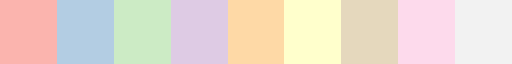

In [13]:
cmap = plt.get_cmap("Pastel1")
cmap


In [14]:
def add_position_label(
    df: pd.DataFrame, vertices: list[tuple[float, float]], label_as: str
) -> None:
    if "position" not in df.columns:
        df["position"] = np.select(
            [df["extant"].astype(bool), df["is_early"]],
            ["unsampled", "early snapshot"],
            default="inner node",
        )
    in_shape = (
        matplotlib.path.Path(vertices).contains_points(
            np.vstack([df["row"].to_numpy(), df["col"].to_numpy()]).T
        )
        & df["extant"]
    )
    df["position"] = np.select([in_shape], [label_as], default=df["position"])


### Outlier CA

The outlier pattern is a square, tilted about 17.6 degrees off the grid axes, with a detached band of replicators running along one side.

- **Border**: that band. Its depth stays close to 200 cells as the pattern grows, so rather than scaling up the reference polygon (which would take in part of the interior), the region is laid `OUTLIER_BORDER_DEPTH` cells deep behind the front.
- **Middle**: the reference polygon, scaled about the seed in proportion to run length.


In [15]:
REFERENCE_MIDDLE_SAMPLE = [(1600, 525), (1900, 625), (1475, 1800), (1175, 1700)]
OUTLIER_TILT = np.arctan2(1650, 5200)  # angle of border band off row axis
OUTLIER_BORDER_DEPTH = 210  # cells


def make_outlier_regions(df: pd.DataFrame) -> dict:
    center = np.array(df.attrs["seed_center"])
    factor = df.attrs["num_steps"] / REFERENCE_NUM_STEPS

    # unit vectors, as (row, col), along and across the border band
    along = np.array([np.cos(OUTLIER_TILT), np.sin(OUTLIER_TILT)])
    across = np.array([-np.sin(OUTLIER_TILT), np.cos(OUTLIER_TILT)])
    extant = df.loc[df["extant"], ["row", "col"]].to_numpy() - center
    front = (extant @ across).min()
    half_length = 1.5 * np.abs(extant @ along).max()
    border = [
        center + u * along + v * across
        for u, v in (
            (-half_length, front - 1),
            (half_length, front - 1),
            (half_length, front + OUTLIER_BORDER_DEPTH),
            (-half_length, front + OUTLIER_BORDER_DEPTH),
        )
    ]

    reference_center = (REFERENCE_GRID_SIZE - 1) / 2
    middle = [
        center + (np.array(vertex) - reference_center) * factor
        for vertex in REFERENCE_MIDDLE_SAMPLE
    ]
    return {"sampled border": border, "sampled middle": middle}


### Control CA

The control pattern is a rounded blob without a distinct border structure, so regions are laid out to be comparable in geometry and tip count to the outlier's.

- **Border**: cells within 8% of the front radius of the front, along the upper left edge of the blob as plotted, i.e., toward low column and high row (the outlier border is about 7.5% of the front distance deep).
- **Middle**: a rectangular strip through the center.


In [16]:
CONTROL_BORDER_DEPTH_FRAC = 0.08
# span of border, as angle from low col direction toward high row direction
CONTROL_BORDER_ARC = (np.deg2rad(10), np.deg2rad(80))
CONTROL_MIDDLE_HALF_EXTENT_FRAC = (0.2, 0.6)  # (rows, cols)


def make_control_regions(df: pd.DataFrame) -> dict:
    extant = df.loc[df["extant"], ["row", "col"]].to_numpy()
    center = extant.mean(axis=0)
    drow, dcol = (extant - center).T
    angle = np.arctan2(drow, -dcol)  # zero is toward low col
    radius = np.hypot(drow, dcol)

    # trace front over arc
    edges = np.linspace(*CONTROL_BORDER_ARC, 121)
    bins = np.digitize(angle, edges) - 1
    in_arc = (bins >= 0) & (bins < len(edges) - 1)
    front = np.zeros(len(edges) - 1)
    np.maximum.at(front, bins[in_arc], radius[in_arc])
    front_radius = front.mean()
    depth = CONTROL_BORDER_DEPTH_FRAC * front_radius

    def trace(radii: np.ndarray) -> list:
        mids = (edges[:-1] + edges[1:]) / 2
        return [
            center + r * np.array([np.sin(a), -np.cos(a)])
            for a, r in zip(mids, radii)
        ]

    border = trace(front + 1) + trace(front - depth)[::-1]

    half_rows, half_cols = (
        np.array(CONTROL_MIDDLE_HALF_EXTENT_FRAC) * front_radius
    )
    middle = [
        center + np.array(offset)
        for offset in (
            (-half_rows, -half_cols),
            (-half_rows, half_cols),
            (half_rows, half_cols),
            (half_rows, -half_cols),
        )
    ]
    return {"sampled border": border, "sampled middle": middle}


In [17]:
regions = {
    "outlier": make_outlier_regions(phylos["outlier"]),
    "control": make_control_regions(phylos["control"]),
}
for name, df in phylos.items():
    for label, vertices in regions[name].items():
        add_position_label(df, vertices, label)

pd.DataFrame(
    {name: df["position"].value_counts() for name, df in phylos.items()},
)


,outlier,control
position,,
early snapshot,1107073,1093119
inner node,135664,344101
sampled border,16293,32455
sampled middle,169718,167712
unsampled,977821,958954


The same regions are also laid out on the early snapshot, for a second view of the persistence filter that starts from early-snapshot cells sampled by region and asks which of their lineages go on to have descendants.


In [18]:
def label_early_positions(df: pd.DataFrame, make_regions: typing.Callable):
    # Lay out regions on early snapshot, as if the run had ended there.
    early_df = df.copy()
    early_df["extant"] = early_df["is_early"]
    early_df.attrs["num_steps"] = (
        df.attrs["num_steps"] - df.attrs["snapshot_lookback"]
    )
    points = np.vstack([df["row"].to_numpy(), df["col"].to_numpy()]).T
    position = np.where(df["is_early"], "unsampled", "")
    for label, vertices in make_regions(early_df).items():
        in_shape = matplotlib.path.Path(vertices).contains_points(points)
        position = np.where(in_shape & df["is_early"], label, position)
    df["early_position"] = position


label_early_positions(phylos["outlier"], make_outlier_regions)
label_early_positions(phylos["control"], make_control_regions)

pd.DataFrame(
    {
        name: df.loc[df["is_early"], "early_position"].value_counts()
        for name, df in phylos.items()
    },
)


,outlier,control
early_position,,
unsampled,924465,903696
sampled middle,162385,158931
sampled border,20223,30492


## Analysis

Ported from the reference notebook, with the phylogeny passed in as an argument and the tree trimming changed as described next.


### Persistence filter

`mark_persistent_tips` picks one early-snapshot tip for each lineage that carries on to the final snapshot: walking rootward from a final-snapshot tip, the first clade that also holds an early-snapshot tip marks where that lineage was last seen at the early snapshot, and one of the early tips there is kept.
The tree analyzed for a region is the phylogeny of the kept tips that lie in that region of the early snapshot.

An earlier version of this analysis instead laid regions out on the final snapshot and kept the early-snapshot lineages leading to each. That variant is retained as `prep_trimmed_tree_final_sampled`, for the two diagrams that illustrate it.


In [19]:
def get_delta_cutoff_time(df: pd.DataFrame) -> int:
    return df.attrs["snapshot_origin_time"] - round(
        (DELTA_LOOKBACK_FRAC - SNAPSHOT_LOOKBACK_FRAC) * df.attrs["num_steps"]
    )


_early_fates_cache = {}


def mark_early_fates(input_df: pd.DataFrame) -> pd.DataFrame:
    # Whole phylogeny, with early-snapshot and extant tips marked up.
    #
    # Each early cell is flagged persistent if it sits with a lineage that
    # has descendants anywhere in the final snapshot (i.e., it is among the
    # closest early relatives of some extant cell), or transient if not. One
    # cell per lineage is flagged as its representative. Each extant cell is
    # labeled with the early region that its lineage was sampled from.
    if id(input_df) not in _early_fates_cache:
        df = input_df.copy()
        df["is_late"] = df["extant"]
        df = pfl.alifestd_collapse_unifurcations(df)
        df = mark_persistent_tips(
            df,
            early="is_early",
            late="is_late",
            mark_transient_as="is_transient",
            representatives=False,
        )
        df = mark_persistent_tips(
            df,
            early="is_early",
            late="is_late",
            mark_as="is_persistent_representative",
            mark_transient_as="is_transient_representative",
            mark_relative_as="relative",
        )
        relative = df["relative"].to_numpy()
        early_position = df["early_position"].to_numpy()
        df["descendant_of"] = np.where(
            df["is_late"],
            np.where(relative >= 0, early_position[relative], "unsampled"),
            "",
        )
        _early_fates_cache[id(input_df)] = df
    return _early_fates_cache[id(input_df)].copy()


def find_early_fates(input_df: pd.DataFrame) -> pd.DataFrame:
    # Early-snapshot and extant cells, marked up as by `mark_early_fates`.
    df = mark_early_fates(input_df)
    return df[df["is_early"] | df["is_late"]]


_trimmed_tree_cache = {}


def prep_trimmed_tree(input_df: pd.DataFrame, key: str) -> pd.DataFrame:
    # Tree of persistent lineages sampled for `key` on the early snapshot,
    # with one tip per lineage.
    cache_key = (id(input_df), key)
    if cache_key not in _trimmed_tree_cache:
        df = mark_early_fates(input_df)
        df["is_persistent"] = df["is_persistent_representative"] & (
            df["early_position"] == key
        )
        df["extant"] = df["is_persistent"]
        df = pfl.alifestd_prune_extinct_lineages_asexual(df)
        df = pfl.alifestd_collapse_unifurcations(df)
        _trimmed_tree_cache[cache_key] = df
    return _trimmed_tree_cache[cache_key].copy()


_final_sampled_tree_cache = {}


def prep_trimmed_tree_final_sampled(
    input_df: pd.DataFrame, key: str
) -> pd.DataFrame:
    # Variant: tree of early-snapshot tips whose lineages persist to cells
    # sampled for `key` on the final snapshot.
    cache_key = (id(input_df), key)
    if cache_key not in _final_sampled_tree_cache:
        df = input_df.copy()
        df["is_late"] = df["position"] == key
        df["extant"] = df["is_late"] | df["is_early"]
        df = pfl.alifestd_prune_extinct_lineages_asexual(df)
        df = pfl.alifestd_collapse_unifurcations(df)
        df = mark_persistent_tips(df, early="is_early", late="is_late")
        df["extant"] = df["is_persistent"]
        df = pfl.alifestd_prune_extinct_lineages_asexual(df)
        df = pfl.alifestd_collapse_unifurcations(df)
        _final_sampled_tree_cache[cache_key] = df
    return _final_sampled_tree_cache[cache_key].copy()


In [20]:
def plot_regions(df: pd.DataFrame, ax=None):
    ax = sns.scatterplot(
        data=df[df["extant"]],
        x="col",
        y="row",
        s=0.5 / SCALE,
        linewidth=0,
        palette={
            "sampled border": cmap.colors[0],
            "sampled middle": cmap.colors[1],
            "unsampled": cmap.colors[-3],
        },
        hue="position",
        hue_order=["sampled border", "sampled middle", "unsampled"],
        rasterized=True,
        ax=ax,
    )
    ax.set_aspect("equal")
    ax.legend(title="position", markerscale=5 * LINEAR_SCALE)
    return ax


In [21]:
def plot(
    df: pd.DataFrame,
    color_by: typing.Optional[str] = None,
    scatter_kws: dict = {},
    tree_kws: dict = {},
    **kwargs,
):
    return draw_scatter_tree(
        df,
        hue=color_by,
        scatter_kws=dict(
            alpha=0.8,
            edgecolor="none",
            legend=True,
        )
        | scatter_kws,
        scatter_shuffle=1,
        tree_kws=dict(
            edge=dict(
                color="gainsboro",
                linewidth=0.5,
            ),
            margins=-0.05,
            layout_angular=True,
        )
        | tree_kws,
        **kwargs,
    )


In [22]:
def plot_colless_index_trees(input_df: pd.DataFrame, key: str, input_ax=None):
    df = prep_trimmed_tree(input_df, key)
    df[key] = True
    color = cmap.colors[0] if key == "sampled border" else cmap.colors[1]
    ax = plot(
        df,
        color_by=key,
        tree_kws={"edge": {"color": [color]}},
        scatter_kws={"palette": [color], "s": 4},
        collapse_unifurcations=False,
        ax=input_ax,
    )
    ax.get_legend().remove()


In [23]:
TREE_GENERATORS = (pfl.alifestd_make_edge_split, pfl.alifestd_make_leaf_split)


def sample_colless_index_data(input_df: pd.DataFrame, n_samples: int):
    data = {
        key: {"source": [], "colless_index": []}
        for key in ("sampled border", "sampled middle")
    }
    observed = {}
    leaf_node_counts = {}

    for key in "sampled border", "sampled middle":
        df = prep_trimmed_tree(input_df, key)
        df = pfl.alifestd_mark_colless_like_index_mdm_asexual(df)
        observed[key] = df["colless_like_index_mdm"].iloc[0]
        leaf_node_count = pfl.alifestd_count_leaf_nodes(df)
        leaf_node_counts[key] = leaf_node_count
        for _ in tqdm(
            range(n_samples),
            desc=f"sampling trees for {key=}",
            mininterval=30,
        ):
            for f in TREE_GENERATORS:
                tree = f(leaf_node_count)
                tree = pfl.alifestd_mark_colless_like_index_mdm_asexual(tree)
                data[key]["source"].append(
                    f.__name__.removeprefix("alifestd_make_")
                )
                data[key]["colless_index"].append(
                    tree["colless_like_index_mdm"].iloc[0]
                )

    return data, observed, leaf_node_counts


In [24]:
def plot_colless_index_data(
    sampled: dict, observed: dict, key: str, input_ax=None
):
    COLOR = "#464c5e"
    OBSERVED_COL_NAME = "observed"

    df = pd.DataFrame(sampled[key])
    lower_bound = df["colless_index"].max()
    upper_bound = df["colless_index"].min()
    for f in TREE_GENERATORS:
        real_name = f.__name__.removeprefix("alifestd_make_")
        lower_bound = min(
            lower_bound,
            df[df["source"] == real_name]["colless_index"].quantile(0.025),
        )
        upper_bound = max(
            upper_bound,
            df[df["source"] == real_name]["colless_index"].quantile(0.975),
        )
    color = cmap.colors[0] if key == "sampled border" else cmap.colors[1]
    ax = sns.boxplot(
        data=df,
        x="source",
        y="colless_index",
        showfliers=False,
        whis=(2.5, 97.5),  # match shaded band
        width=0.2,
        order=("leaf_split", "edge_split", OBSERVED_COL_NAME),
        boxprops={"facecolor": COLOR, "edgecolor": COLOR},
        whiskerprops={"color": COLOR},
        medianprops={"color": COLOR},
        capprops={"linewidth": 0},
        ax=input_ax,
    )
    ax = sns.scatterplot(
        data=pd.DataFrame(
            {
                "colless_index": [observed[key]],
                "source": [OBSERVED_COL_NAME],
            }
        ),
        x="source",
        y="colless_index",
        color=color,
        ax=ax,
    )
    y_max = ax.get_ylim()[1]
    ax.set_ylim([0, y_max * 1.25])
    ax.axhspan(lower_bound, upper_bound, color=f"{COLOR}20")
    ax.text(
        0,
        upper_bound,
        "null models, 95% CI",
        color="gray",
        fontsize="x-small",
        fontstyle="italic",
        ha="left",
        va="bottom",
        transform=ax.get_yaxis_transform(),
    )
    ax.set_xticks(range(3))
    ax.set_xticklabels(
        ["leaf split\nnull", "edge split\nnull", "obsvd.\nvalue"]
    )
    ax.set_xlabel("")
    ax.set_ylabel("colless imbalance")
    ax.yaxis.tick_right()
    ax.yaxis.set_label_position("right")
    sns.despine(ax=ax, top=True, left=True, bottom=False, right=False)
    return ax


In [25]:
def prep_origin_time_delta(input_df: pd.DataFrame) -> pd.DataFrame:
    cutout_dfs = [
        prep_trimmed_tree(input_df, key).pipe(
            pfl.alifestd_mark_origin_time_delta_asexual
        )
        for key in ("sampled border", "sampled middle")
    ]
    return (
        pd.concat(cutout_dfs, keys=["border", "middle"])
        .reset_index(level=0)
        .rename(columns={"level_0": "source"})
    )


def plot_origin_time_delta(input_df: pd.DataFrame, input_ax=None):
    delta_cutoff_time = get_delta_cutoff_time(input_df)
    df = prep_origin_time_delta(input_df)
    original_df = df.copy()
    for src in ("border", "middle"):
        original_df[f"{src}_marker_type"] = "."
        original_df[f"{src}_hue"] = "#ffffff"
    markers = "osDv"

    for i, src in enumerate(("border", "middle")):
        for j, m in enumerate(markers):
            plot_df = df[
                (df["source"] == src) & (df["origin_time"] < delta_cutoff_time)
            ].copy()
            plot_df["marker_col"] = range(len(plot_df))
            plot_df.loc[
                plot_df["marker_col"] % len(markers) != j, "origin_time"
            ] = 1e10
            origin_times = sorted(plot_df["origin_time"].unique())
            colors = sns.dark_palette(
                cmap.colors[i], n_colors=len(origin_times)
            )[1:] + [(0, 0, 0, 0)]
            for id in plot_df[plot_df["marker_col"] % len(markers) == j]["id"]:
                is_id = (original_df["id"] == id) & (
                    original_df["source"] == src
                )
                original_df.loc[is_id, f"{src}_marker_type"] = m
                color_to_be_plotted = colors[
                    origin_times.index(
                        original_df.loc[is_id, "origin_time"].values[0]
                    )
                ]
                original_df.loc[is_id, f"{src}_hue"] = mpl.colors.rgb2hex(
                    color_to_be_plotted
                )
            ax = sns.swarmplot(
                data=plot_df,
                y="origin_time_delta",
                x="source",
                hue="origin_time",
                palette=colors,
                order=("border", "middle"),
                legend=False,
                marker=m,
                ax=input_ax,
            )

    ax.tick_params(
        axis="y",
        which="both",
        labelleft=False,
        left=False,
        labelright=True,
        right=True,
    )
    ax.yaxis.set_label_position("right")
    ax.set_xticks(range(2))
    ax.set_xticklabels(["sampled\nborder", "sampled\nmiddle"])
    ax.set_xlabel("")
    ax.set_ylabel("branch length")
    sns.despine(ax=ax, top=True, left=True, bottom=False, right=False)
    return original_df, ax


In [26]:
def plot_origin_time_delta_trees(
    input_df: pd.DataFrame, marker_info_df: pd.DataFrame, key: str, input_ax=None
):
    df = prep_trimmed_tree(input_df, key)

    src = key[-6:]
    color = cmap.colors[0] if src == "border" else cmap.colors[1]
    is_src = marker_info_df["source"] == src
    markers = list(marker_info_df[is_src][f"{src}_marker_type"])
    palette = list(marker_info_df[is_src][f"{src}_hue"])

    return plot(
        df,
        "id",
        tree_kws={
            "edge": {
                "color": [color],
                "linewidth": 0.01,
            }
        },
        scatter_kws={"markers": markers, "palette": palette, "legend": False},
        collapse_unifurcations=False,
        style="id",
        ax=input_ax,
    )


In [27]:
def plot_persistent_tips(df: pd.DataFrame, ax=None):
    # Early snapshot, with tips kept by the persistence filter highlighted.
    if ax is None:
        ax = plt.gca()
    early_df = df[df["is_early"]]
    ax.scatter(
        early_df["col"],
        early_df["row"],
        s=0.5 / SCALE,
        linewidth=0,
        color=cmap.colors[-3],
        rasterized=True,
    )
    for i, key in enumerate(("sampled border", "sampled middle")):
        tree_df = prep_trimmed_tree_final_sampled(df, key)
        tips_df = tree_df[tree_df["is_persistent"]]
        ax.scatter(
            tips_df["col"],
            tips_df["row"],
            s=6,
            linewidth=0,
            color=sns.dark_palette(cmap.colors[i], n_colors=4)[2],
            label=key.replace("sampled", "persists to"),
        )
    ax.set_aspect("equal")
    ax.set_xlabel("col")
    ax.set_ylabel("row")
    ax.legend(title="early snapshot tip", markerscale=2)
    return ax


In [28]:
_transient_tips_cache = {}


def find_transient_tips(input_df: pd.DataFrame) -> pd.DataFrame:
    # One early-snapshot tip for each lineage without descendants anywhere
    # in the final snapshot. Column `transient_for` names the sampled region
    # holding the lineage's closest extant relatives, if exactly one does.
    if id(input_df) not in _transient_tips_cache:
        df = input_df.copy()
        df["is_late"] = df["extant"]
        df = pfl.alifestd_collapse_unifurcations(df)
        df = mark_persistent_tips(
            df,
            early="is_early",
            late="is_late",
            mark_transient_as="is_transient",
        )
        ancestor_ids = df["ancestor_id"].to_numpy()
        has_late = df["is_late"].to_numpy().copy()
        has_region = {
            key: (df["position"] == key).to_numpy().copy()
            for key in ("sampled border", "sampled middle")
        }
        for i in range(len(df) - 1, 0, -1):
            a = ancestor_ids[i]
            has_late[a] |= has_late[i]
            for flags in has_region.values():
                flags[a] |= flags[i]

        transient_for = []
        for i in np.flatnonzero(df["is_transient"].to_numpy()):
            while not has_late[i] and ancestor_ids[i] != i:
                i = ancestor_ids[i]
            regions = [key for key, flags in has_region.items() if flags[i]]
            transient_for.append(regions[0] if len(regions) == 1 else "")

        df = df[df["is_transient"]].copy()
        df["transient_for"] = transient_for
        _transient_tips_cache[id(input_df)] = df
    return _transient_tips_cache[id(input_df)].copy()


In [29]:
def plot_persistence_filter(df: pd.DataFrame, ax=None):
    # Final snapshot with sampled regions, overlaid with the early-snapshot
    # tips that the persistence filter keeps for each region.
    if ax is None:
        ax = plt.gca()
    keys = ("sampled border", "sampled middle")
    light = {
        "sampled border": cmap.colors[0],
        "sampled middle": cmap.colors[1],
        "unsampled": cmap.colors[-3],
    }
    dark = {
        key: sns.dark_palette(light[key], n_colors=4)[2] for key in keys
    }
    for position in "unsampled", *keys:
        position_df = df[df["position"] == position]
        ax.scatter(
            position_df["col"],
            position_df["row"],
            s=3 / SCALE,
            linewidth=0,
            color=light[position],
            rasterized=True,
        )
    transient_df = find_transient_tips(df)
    for key in keys:
        key_df = transient_df[transient_df["transient_for"] == key]
        ax.scatter(
            key_df["col"],
            key_df["row"],
            s=5,
            linewidth=0.5,
            marker="x",
            color=dark[key],
            rasterized=True,
        )
    for key in keys:
        tree_df = prep_trimmed_tree_final_sampled(df, key)
        tips_df = tree_df[tree_df["is_persistent"]]
        ax.scatter(
            tips_df["col"],
            tips_df["row"],
            s=9,
            linewidth=0.6,
            facecolor="none",
            edgecolor=dark[key],
        )

    def make_handle(
        color, size: float, label: str, marker: str = "o", **kwargs
    ) -> mpl.lines.Line2D:
        return mpl.lines.Line2D(
            [],
            [],
            marker=marker,
            linestyle="",
            color=color,
            markersize=size,
            label=label,
            **kwargs,
        )

    # legend fills column by column; pair each region with its tips
    handles = []
    for key in keys:
        handles.append(
            make_handle(light[key], 6, key.replace("sampled", "extant"))
        )
        handles.append(
            make_handle(
                dark[key],
                4,
                key.replace("sampled", "persistent"),
                markerfacecolor="none",
            )
        )
        handles.append(
            make_handle(
                dark[key], 4, key.replace("sampled", "transient"), marker="x"
            )
        )
    handles.append(make_handle(light["unsampled"], 6, "extant unsampled"))
    # blank entry, so that each region's entries fill one column
    handles.append(make_handle("none", 0, ""))
    ax.legend(handles=handles, fontsize="x-small")
    sns.move_legend(
        ax,
        "lower center",
        bbox_to_anchor=(0.5, 1),
        ncol=3,
        title=None,
        frameon=False,
    )
    ax.set_aspect("equal")
    ax.set_xlabel("CA col")
    ax.set_ylabel("CA row")
    sns.despine(ax=ax, top=True, right=True)
    return ax


In [30]:
def plot_persistence_filter_early(df: pd.DataFrame, ax=None):
    # Early snapshot over the final snapshot. Every early cell in a sampled
    # region is marked persistent if its lineage has descendants in the final
    # snapshot and transient if not; extant cells are colored by the early
    # region that their lineage was sampled from.
    if ax is None:
        ax = plt.gca()
    keys = ("sampled border", "sampled middle")
    region_colors = {
        "sampled border": cmap.colors[0],
        "sampled middle": cmap.colors[1],
    }
    marker_colors = {
        key: sns.dark_palette(color, n_colors=4)[1]
        for key, color in region_colors.items()
    }
    descendant_colors = dict(region_colors)
    descendant_colors["unsampled"] = "0.9"
    unsampled_color = cmap.colors[-3]

    def scatter(cells_df: pd.DataFrame, color, zorder: float) -> None:
        ax.scatter(
            cells_df["col"],
            cells_df["row"],
            s=3 / SCALE,
            linewidth=0,
            color=color,
            rasterized=True,
            zorder=zorder,
        )

    # bottom to top: unsampled extant, unsampled early, descendants, markers
    fates_df = find_early_fates(df)
    scatter(
        fates_df[fates_df["descendant_of"] == "unsampled"],
        descendant_colors["unsampled"],
        zorder=1,
    )
    scatter(
        fates_df[fates_df["early_position"] == "unsampled"],
        unsampled_color,
        zorder=1.5,
    )
    for key in keys:
        scatter(
            fates_df[fates_df["descendant_of"] == key],
            descendant_colors[key],
            zorder=2,
        )
    # every early cell sampled in a region gets a marker; persistent circles
    # are drawn in a stronger color, on top of all transient crosses
    bright_colors = dict(zip(keys, ["#b2182b", "#2166ac"]))
    marker_scale = 1 / LINEAR_SCALE
    for key in keys:
        key_df = fates_df[fates_df["early_position"] == key]
        transient_df = key_df[key_df["is_transient"]]
        ax.scatter(
            transient_df["col"],
            transient_df["row"],
            s=5 * marker_scale,
            linewidth=0.5 * marker_scale,
            marker="x",
            color=marker_colors[key],
            rasterized=True,
            zorder=3,
        )
    for key in keys:
        key_df = fates_df[fates_df["early_position"] == key]
        persistent_df = key_df[key_df["is_persistent"]]
        ax.scatter(
            persistent_df["col"],
            persistent_df["row"],
            s=max(9 * marker_scale, 6),
            linewidth=max(0.6 * marker_scale, 0.7),
            facecolor="none",
            edgecolor=bright_colors[key],
            rasterized=True,
            zorder=4,
        )

    def make_handle(
        color, label: str, marker: str = "o", size: float = 6, **kwargs
    ) -> mpl.lines.Line2D:
        return mpl.lines.Line2D(
            [],
            [],
            marker=marker,
            linestyle="",
            color=color,
            markersize=size,
            label=label,
            **kwargs,
        )

    # legend fills column by column; keep each region's entries together
    handles = []
    for key in keys:
        region = key.removeprefix("sampled ")
        handles.append(
            make_handle(
                bright_colors[key],
                f"persistent {region}",
                size=4,
                markerfacecolor="none",
            )
        )
        handles.append(
            make_handle(
                marker_colors[key], f"transient {region}", marker="x", size=4
            )
        )
        handles.append(
            make_handle(descendant_colors[key], f"{region} descendant")
        )
    handles.append(make_handle(unsampled_color, "unsampled early"))
    handles.append(
        make_handle(descendant_colors["unsampled"], "unsampled extant")
    )
    handles.append(make_handle("none", "", size=0))
    ax.legend(handles=handles, fontsize="x-small")
    sns.move_legend(
        ax,
        "lower center",
        bbox_to_anchor=(0.5, 1),
        ncol=3,
        title=None,
        frameon=False,
    )
    ax.set_aspect("equal")
    ax.set_xlabel("CA col")
    ax.set_ylabel("CA row")
    sns.despine(ax=ax, top=True, right=True)
    return ax


### Figure assembly


In [31]:
null_samples = {}


def show_regions(name: str) -> None:
    with tp.teed(
        plot_regions,
        phylos[name],
        teeplot_outattrs={"ca": name},
        teeplot_subdir=teeplot_subdir,
    ):
        ...


def show_persistent_tips(name: str) -> None:
    with tp.teed(
        plot_persistent_tips,
        phylos[name],
        teeplot_outattrs={"ca": name},
        teeplot_subdir=teeplot_subdir,
    ):
        ...


def show_persistence_filter_early(name: str) -> None:
    with tp.teed(
        plot_persistence_filter_early,
        phylos[name],
        teeplot_outattrs={"ca": name},
        teeplot_subdir=teeplot_subdir,
    ):
        ...


def show_persistence_filter(name: str) -> None:
    with tp.teed(
        plot_persistence_filter,
        phylos[name],
        teeplot_outattrs={"ca": name},
        teeplot_subdir=teeplot_subdir,
    ):
        ...


def show_colless(name: str) -> None:
    with tp.teed(
        plt.subplots,
        2,
        2,
        tight_layout=True,
        figsize=(5, 5),
        gridspec_kw={"width_ratios": [1, 1.3]},
        teeplot_outattrs={"ca": name, "viz": "plot_colless_data"},
        teeplot_subdir=teeplot_subdir,
    ) as (fig, axes):
        df = phylos[name]
        plot_colless_index_trees(df, "sampled border", axes[0][0])
        plot_colless_index_trees(df, "sampled middle", axes[1][0])
        null_samples[name] = sample_colless_index_data(df, N_NULL_SAMPLES)
        sampled, observed, __ = null_samples[name]
        plot_colless_index_data(sampled, observed, "sampled border", axes[0][1])
        axes[0][1].set_xlabel(None)
        axes[0][1].set_xticks([])
        axes[0][1].spines["bottom"].set_visible(False)
        plot_colless_index_data(sampled, observed, "sampled middle", axes[1][1])


def show_branch_lengths(name: str) -> None:
    with tp.teed(
        plt.subplot_mosaic,
        [["border", "wait_times"], ["middle", "wait_times"]],
        tight_layout=True,
        figsize=(5, 5),
        gridspec_kw={"width_ratios": [1, 1.5]},
        teeplot_outattrs={"ca": name, "viz": "plot_branch_length_data"},
        teeplot_subdir=teeplot_subdir,
    ) as (fig, axes):
        df = phylos[name]
        marker_info_df, __ = plot_origin_time_delta(df, axes["wait_times"])
        plot_origin_time_delta_trees(
            df, marker_info_df, "sampled border", axes["border"]
        )
        plot_origin_time_delta_trees(
            df, marker_info_df, "sampled middle", axes["middle"]
        )


## Outlier CA

### (a) Sampled regions

Extant cells, with those sampled for "border" (red) and "middle" (blue) highlighted.


teeplots/2026-11-27-outlier-plots-scaled-control/ca=outlier+viz=plot-regions+ext=.pdf


/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/teeplot/teeplot.py:336: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(
/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/teeplot/teeplot.py:336: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(


teeplots/2026-11-27-outlier-plots-scaled-control/ca=outlier+viz=plot-regions+ext=.png


/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


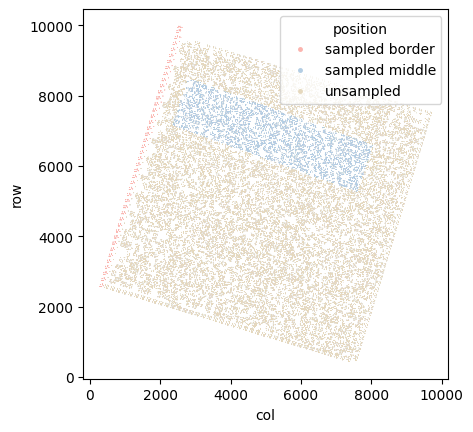

In [32]:
show_regions("outlier")


Variant with regions sampled on the final snapshot (not the one used for the trees below): early snapshot, with the tips kept for each final-snapshot region highlighted.


/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/phyloframe/legacy/_alifestd_assign_contiguous_ids.py:41: NumbaTypeSafetyWarning: unsafe cast from uint64 to int64. Precision may be lost.
  [reassignment[ancestor_id] for ancestor_id in ancestor_ids]


teeplots/2026-11-27-outlier-plots-scaled-control/ca=outlier+viz=plot-persistent-tips+ext=.pdf


/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/teeplot/teeplot.py:336: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(
/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/teeplot/teeplot.py:336: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(


teeplots/2026-11-27-outlier-plots-scaled-control/ca=outlier+viz=plot-persistent-tips+ext=.png


/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


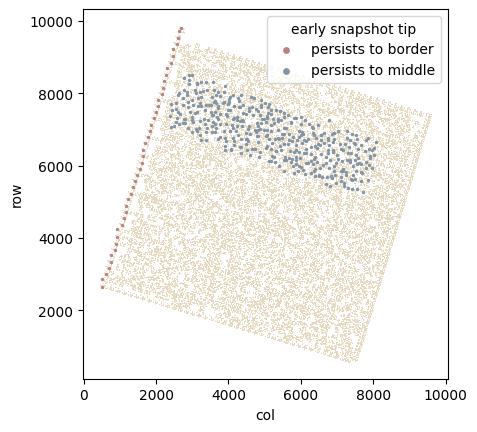

In [33]:
show_persistent_tips("outlier")


The same variant in one panel: extant cells, i.e., the final snapshot, with sampled regions highlighted (light), overlaid with the persistent early-snapshot tips kept for each region (open circles).
Crosses mark transient lineages, one per early-snapshot lineage without descendants anywhere in the final snapshot.
A transient lineage is assigned to the border or the middle when its closest extant relatives include cells sampled from that region and none from the other; transient lineages related to neither, or to both, are not drawn.
Early-snapshot lineages that persist only to unsampled cells are not drawn either.


teeplots/2026-11-27-outlier-plots-scaled-control/ca=outlier+viz=plot-persistence-filter+ext=.pdf
teeplots/2026-11-27-outlier-plots-scaled-control/ca=outlier+viz=plot-persistence-filter+ext=.png


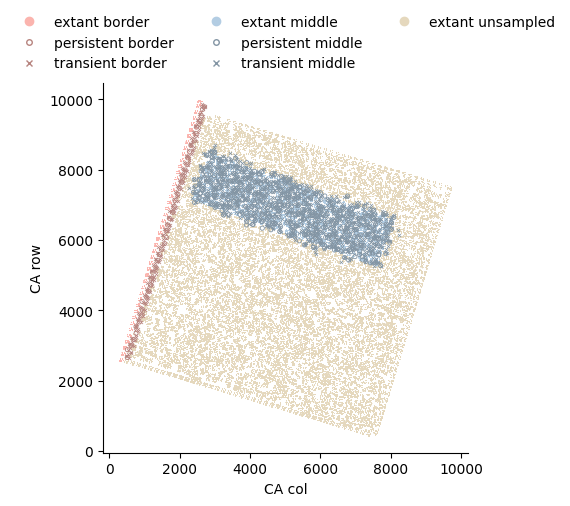

In [34]:
show_persistence_filter("outlier")


The filter as used for the trees below: regions are sampled on the early snapshot. Every early-snapshot cell in a sampled region is drawn as a hollow circle if it sits with a lineage that has descendants anywhere in the final snapshot (persistent), or as a cross if not (transient). Final-snapshot cells are drawn underneath in pale colors, by whether their lineage traces to the early border sample, the early middle sample, or unsampled early cells.


teeplots/2026-11-27-outlier-plots-scaled-control/ca=outlier+viz=plot-persistence-filter-early+ext=.pdf
teeplots/2026-11-27-outlier-plots-scaled-control/ca=outlier+viz=plot-persistence-filter-early+ext=.png


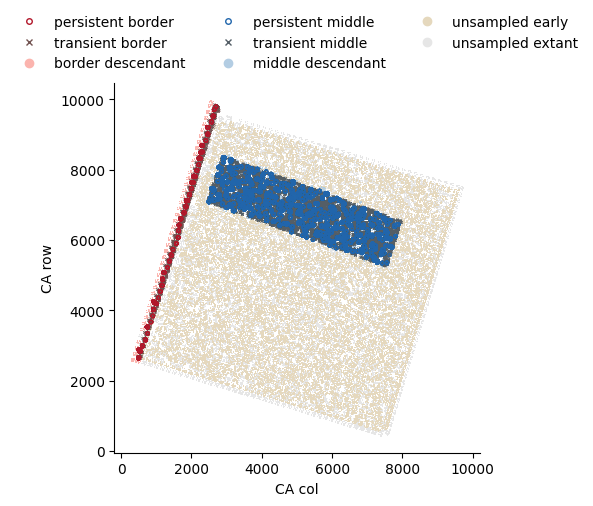

In [35]:
show_persistence_filter_early("outlier")


### (b) Tree imbalance

Trees of the persistent lineages sampled in each early-snapshot region (left), and their Colless-like imbalance compared against random trees with the same number of leaves generated by edge splitting and leaf splitting (right).
Whiskers span the 2.5th to 97.5th percentiles of each null model, and the shaded band spans both sets of whiskers.


sampling trees for key='sampled middle': 100%|██████████| 1000/1000 [01:06<00:00, 14.94it/s]


teeplots/2026-11-27-outlier-plots-scaled-control/ca=outlier+viz=plot_colless_data+ext=.pdf
teeplots/2026-11-27-outlier-plots-scaled-control/ca=outlier+viz=plot_colless_data+ext=.png


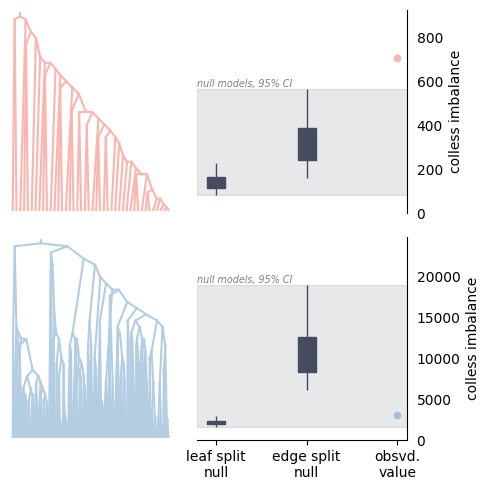

In [36]:
show_colless("outlier")


### (c) Branch lengths

Inner branch lengths of the same trees (left), as a swarmplot with markers matched to tree nodes (right).


/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/seaborn/categorical.py:3399: UserWarning: 29.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/seaborn/categorical.py:3399: UserWarning: 19.5% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/seaborn/categorical.py:3399: UserWarning: 44.9% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/seaborn/categorical.py:3399: UserWarning: 19.5% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


teeplots/2026-11-27-outlier-plots-scaled-control/ca=outlier+viz=plot_branch_length_data+ext=.pdf


/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/seaborn/categorical.py:3399: UserWarning: 14.6% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/seaborn/categorical.py:3399: UserWarning: 40.6% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/seaborn/categorical.py:3399: UserWarning: 40.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/seaborn/categorical.py:3399: UserWarning: 14.6% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


teeplots/2026-11-27-outlier-plots-scaled-control/ca=outlier+viz=plot_branch_length_data+ext=.png


/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/seaborn/categorical.py:3399: UserWarning: 40.9% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


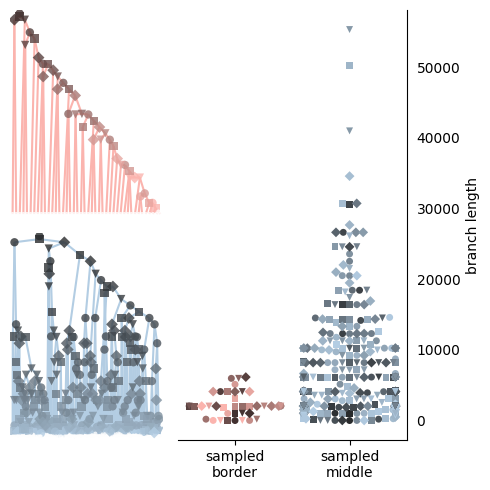

In [37]:
show_branch_lengths("outlier")


## Non-replicator control CA

### (a) Sampled regions

Extant cells, with those sampled for "border" (red) and "middle" (blue) highlighted.


teeplots/2026-11-27-outlier-plots-scaled-control/ca=control+viz=plot-regions+ext=.pdf


/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/teeplot/teeplot.py:336: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(
/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/teeplot/teeplot.py:336: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(


teeplots/2026-11-27-outlier-plots-scaled-control/ca=control+viz=plot-regions+ext=.png


/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


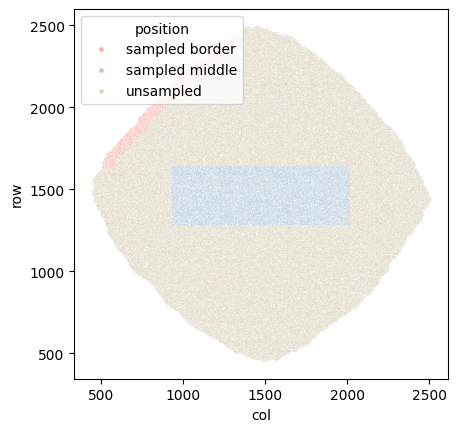

In [38]:
show_regions("control")


Variant with regions sampled on the final snapshot (not the one used for the trees below): early snapshot, with the tips kept for each final-snapshot region highlighted.


teeplots/2026-11-27-outlier-plots-scaled-control/ca=control+viz=plot-persistent-tips+ext=.pdf


/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/teeplot/teeplot.py:336: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(
/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/teeplot/teeplot.py:336: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(


teeplots/2026-11-27-outlier-plots-scaled-control/ca=control+viz=plot-persistent-tips+ext=.png


/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


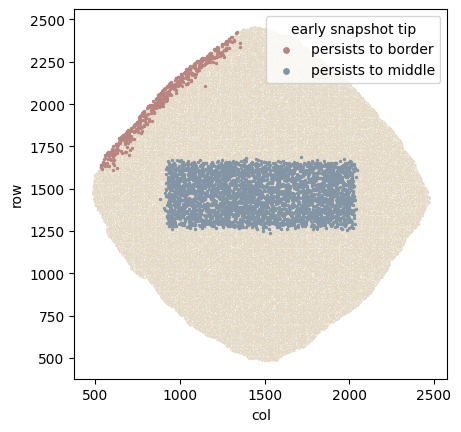

In [39]:
show_persistent_tips("control")


The same variant in one panel: extant cells, i.e., the final snapshot, with sampled regions highlighted (light), overlaid with the persistent early-snapshot tips kept for each region (open circles).
Crosses mark transient lineages, one per early-snapshot lineage without descendants anywhere in the final snapshot.
A transient lineage is assigned to the border or the middle when its closest extant relatives include cells sampled from that region and none from the other; transient lineages related to neither, or to both, are not drawn.
Early-snapshot lineages that persist only to unsampled cells are not drawn either.


teeplots/2026-11-27-outlier-plots-scaled-control/ca=control+viz=plot-persistence-filter+ext=.pdf
teeplots/2026-11-27-outlier-plots-scaled-control/ca=control+viz=plot-persistence-filter+ext=.png


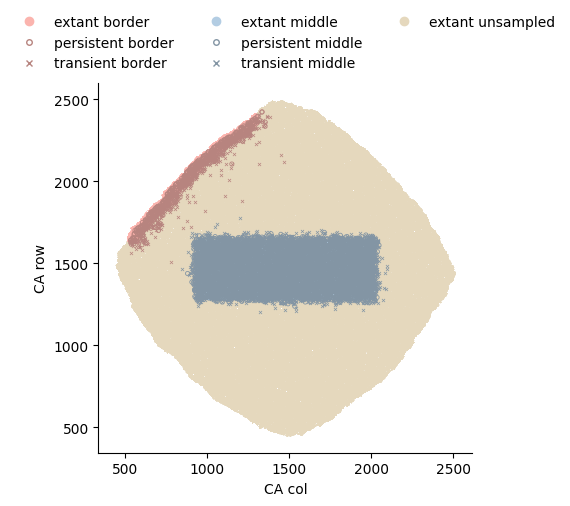

In [40]:
show_persistence_filter("control")


The filter as used for the trees below: regions are sampled on the early snapshot. Every early-snapshot cell in a sampled region is drawn as a hollow circle if it sits with a lineage that has descendants anywhere in the final snapshot (persistent), or as a cross if not (transient). Final-snapshot cells are drawn underneath in pale colors, by whether their lineage traces to the early border sample, the early middle sample, or unsampled early cells.


teeplots/2026-11-27-outlier-plots-scaled-control/ca=control+viz=plot-persistence-filter-early+ext=.pdf
teeplots/2026-11-27-outlier-plots-scaled-control/ca=control+viz=plot-persistence-filter-early+ext=.png


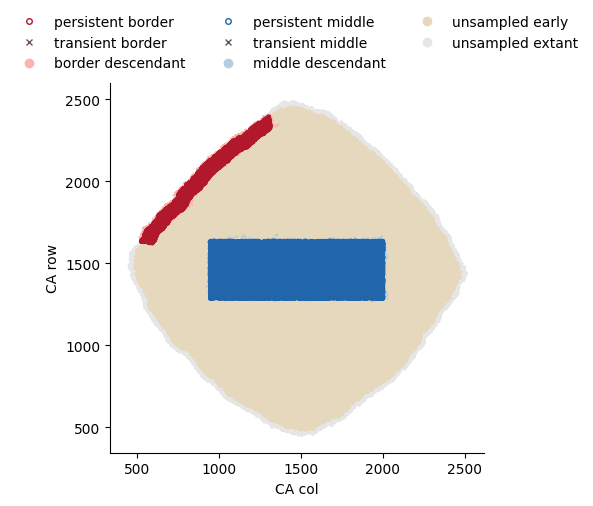

In [41]:
show_persistence_filter_early("control")


### (b) Tree imbalance

Trees of the persistent lineages sampled in each early-snapshot region (left), and their Colless-like imbalance compared against random trees with the same number of leaves generated by edge splitting and leaf splitting (right).
Whiskers span the 2.5th to 97.5th percentiles of each null model, and the shaded band spans both sets of whiskers.


sampling trees for key='sampled middle': 100%|██████████| 1000/1000 [07:35<00:00,  2.20it/s]


teeplots/2026-11-27-outlier-plots-scaled-control/ca=control+viz=plot_colless_data+ext=.pdf
teeplots/2026-11-27-outlier-plots-scaled-control/ca=control+viz=plot_colless_data+ext=.png


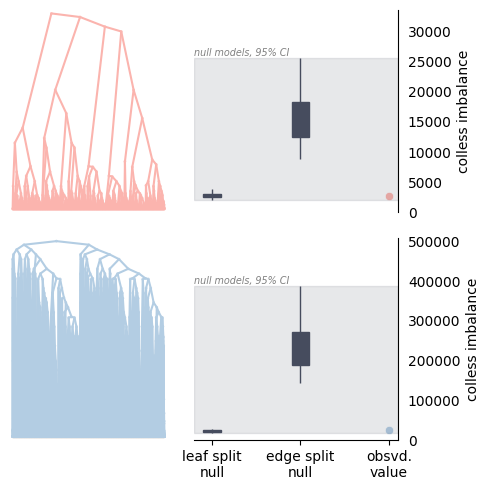

In [42]:
show_colless("control")


### (c) Branch lengths

Inner branch lengths of the same trees (left), as a swarmplot with markers matched to tree nodes (right).


/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/seaborn/categorical.py:3399: UserWarning: 38.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/seaborn/categorical.py:3399: UserWarning: 51.8% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/seaborn/categorical.py:3399: UserWarning: 51.8% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/seaborn/categorical.py:3399: UserWarning: 68.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


teeplots/2026-11-27-outlier-plots-scaled-control/ca=control+viz=plot_branch_length_data+ext=.pdf


/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/seaborn/categorical.py:3399: UserWarning: 69.8% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/seaborn/categorical.py:3399: UserWarning: 80.8% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/seaborn/categorical.py:3399: UserWarning: 69.8% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/seaborn/categorical.py:3399: UserWarning: 80.9% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


teeplots/2026-11-27-outlier-plots-scaled-control/ca=control+viz=plot_branch_length_data+ext=.png


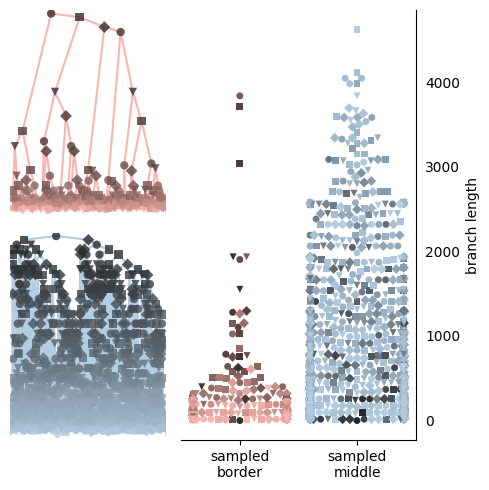

In [43]:
show_branch_lengths("control")


## Tips and replicator units

Replicator units in the outlier CA are counted as connected clusters of cells, after closing gaps of up to 8 cells within a unit.
(The control CA is one dense mass, without discrete units to count.)
Tips number fewer than the units sampled at the early snapshot, since only some units have descendants in the final snapshot.


In [44]:
def count_units(df: pd.DataFrame, key: str, dilation: int = 4) -> int:
    # number of early-snapshot replicator units sampled for `key`
    early = df.loc[df["is_early"], ["row", "col"]].to_numpy().astype(int)
    early = early - early.min(axis=0) + dilation
    cells = np.zeros(early.max(axis=0) + dilation + 1, dtype=bool)
    cells[tuple(early.T)] = True
    labels, __ = scipy_ndimage.label(
        scipy_ndimage.binary_dilation(cells, iterations=dilation),
        structure=np.ones((3, 3)),
    )
    is_key = (df.loc[df["is_early"], "early_position"] == key).to_numpy()
    return len(np.unique(labels[tuple(early[is_key].T)]))


pd.DataFrame(
    {
        key: {
            "num early snapshot cells": (
                phylos["outlier"]["early_position"] == key
            ).sum(),
            "num early snapshot replicator units": count_units(
                phylos["outlier"], key
            ),
            "num persistent tips": pfl.alifestd_count_leaf_nodes(
                prep_trimmed_tree(phylos["outlier"], key),
            ),
        }
        for key in ("sampled border", "sampled middle")
    },
)


,sampled border,sampled middle
num early snapshot cells,20223,162385
num early snapshot replicator units,310,2402
num persistent tips,42,353


## Summary

Observed imbalance of each tree, the median, mean, and 95% interval (2.5th to 97.5th percentiles) of each null model, and where the observed value falls within each null model.
The shaded band in the imbalance figures runs from the lower of the two 2.5th percentiles to the higher of the two 97.5th percentiles.


In [45]:
records = []
for name, (sampled, observed, leaf_node_counts) in null_samples.items():
    for key in sampled:
        null_df = pd.DataFrame(sampled[key])
        record = {
            "ca": name,
            "region": key,
            "num early cells sampled": (
                phylos[name]["early_position"] == key
            ).sum(),
            "num tree leaves": leaf_node_counts[key],
            "observed colless": observed[key],
        }
        for source, group in null_df.groupby("source"):
            values = group["colless_index"]
            record[f"{source} null 2.5th percentile"] = values.quantile(0.025)
            record[f"{source} null median"] = values.median()
            record[f"{source} null mean"] = values.mean()
            record[f"{source} null 97.5th percentile"] = values.quantile(0.975)
            record[
                f"observed percentile in {source} null"
            ] = scipy_stats.percentileofscore(
                values, observed[key], kind="mean"
            )
        records.append(record)

pd.DataFrame(records).set_index(["ca", "region"]).T


ca                                            outlier                 \
region                                 sampled border sampled middle   
num early cells sampled                  20223.000000  162385.000000   
num tree leaves                             42.000000     353.000000   
observed colless                           709.301630    3108.935384   
edge_split null 2.5th percentile           160.709124    6095.369529   
edge_split null median                     308.724810   10086.498815   
edge_split null mean                       322.457962   10733.652355   
edge_split null 97.5th percentile          565.176897   19007.242541   
observed percentile in edge_split null      99.800000       0.000000   
leaf_split null 2.5th percentile            82.921953    1539.796885   
leaf_split null median                     136.502292    2129.180614   
leaf_split null mean                       141.943248    2158.731446   
leaf_split null 97.5th percentile          228.386195    2986.625503   
observed percentile in leaf_split null     100.000000      98.900000   

ca                                            control                 
region                                 sampled border sampled middle  
num early cells sampled                  30492.000000  158931.000000  
num tree leaves                            451.000000    2643.000000  
observed colless                          2718.564343   26060.456308  
edge_split null 2.5th percentile          8910.633626  143212.113397  
edge_split null median                   15087.968316  224707.649540  
edge_split null mean                     15663.783462  235644.711998  
edge_split null 97.5th percentile        25662.112002  388880.742374  
observed percentile in edge_split null       0.000000       0.000000  
leaf_split null 2.5th percentile          2126.597276   18352.637506  
leaf_split null median                    2797.659129   22384.462337  
leaf_split null mean                      2855.021985   22756.460424  
leaf_split null 97.5th percentile         3805.607363   29096.229015  
observed percentile in leaf_split null      42.800000      87.900000

Median, mean, and 95% interval of inner branch lengths of the trees, as a fraction of run length, and a Mann-Whitney U test of border against middle.


In [46]:
records = []
for name, df in phylos.items():
    delta_cutoff_time = get_delta_cutoff_time(df)
    delta_df = prep_origin_time_delta(df)
    delta_df = delta_df[delta_df["origin_time"] < delta_cutoff_time]
    delta_df = delta_df[delta_df["origin_time_delta"].notna()]
    fracs = {
        src: group["origin_time_delta"] / df.attrs["num_steps"]
        for src, group in delta_df.groupby("source")
    }
    test = scipy_stats.mannwhitneyu(fracs["border"], fracs["middle"])
    records.append(
        {
            "ca": name,
            **{f"{src} num branches": len(v) for src, v in fracs.items()},
            **{
                f"{src} 2.5th percentile length": v.quantile(0.025)
                for src, v in fracs.items()
            },
            **{f"{src} median length": v.median() for src, v in fracs.items()},
            **{f"{src} mean length": v.mean() for src, v in fracs.items()},
            **{
                f"{src} 97.5th percentile length": v.quantile(0.975)
                for src, v in fracs.items()
            },
            "mann-whitney u": test.statistic,
            "p": test.pvalue,
        }
    )

pd.DataFrame(records).set_index("ca").T


ca,outlier,control
border num branches,4.100000e+01,3.280000e+02
middle num branches,3.030000e+02,2.116000e+03
border 2.5th percentile length,2.385141e-04,2.981181e-03
middle 2.5th percentile length,1.681524e-03,2.981181e-03
border median length,3.052980e-02,1.937768e-02
middle median length,6.129811e-02,5.366126e-02
border mean length,3.340360e-02,4.169109e-02
middle mean length,1.134477e-01,1.127326e-01
border 97.5th percentile length,8.896574e-02,2.379728e-01
middle 97.5th percentile length,4.038639e-01,5.038196e-01
